<a href="https://colab.research.google.com/github/SrEffry/Mamografias/blob/main/Mamografias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install pydicom

import pydicom
from pathlib import Path

carpeta = Path("/content")          # Cambiado a la raíz de Colab para detectar tus archivos
archivos = list(carpeta.glob("*.dcm"))
print("Archivos .dcm encontrados:", len(archivos))

for f in archivos[:10]:
    ds = pydicom.dcmread(f)
    print(f.name,
          "| paciente:", ds.get("PatientID"),
          "| serie:", ds.get("SeriesDescription"),
          "| tamaño:", ds.pixel_array.shape if "pixel_array" in dir(ds) else "Sin imagen")

Archivos .dcm encontrados: 4
e35e53fd-5312-406e-ad9f-4c11e725e53f.dcm | paciente: Mass-Training_P_00001_LEFT_CC | serie: full mammogram images | tamaño: (4808, 3024)
7bce52a1-13c4-44e0-9ac9-bf67aba44baa.dcm | paciente: Mass-Training_P_02092_LEFT_CC_1 | serie: cropped images | tamaño: (434, 387)
0726551a-53c5-4312-94a6-e91ca86b4dd4.dcm | paciente: Mass-Training_P_02092_LEFT_CC_1 | serie: ROI mask images | tamaño: (4556, 2585)
451ce9f0-468b-46f9-b85e-ed82433a27c8.dcm | paciente: Mass-Training_P_02092_LEFT_MLO | serie: full mammogram images | tamaño: (5341, 3496)


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


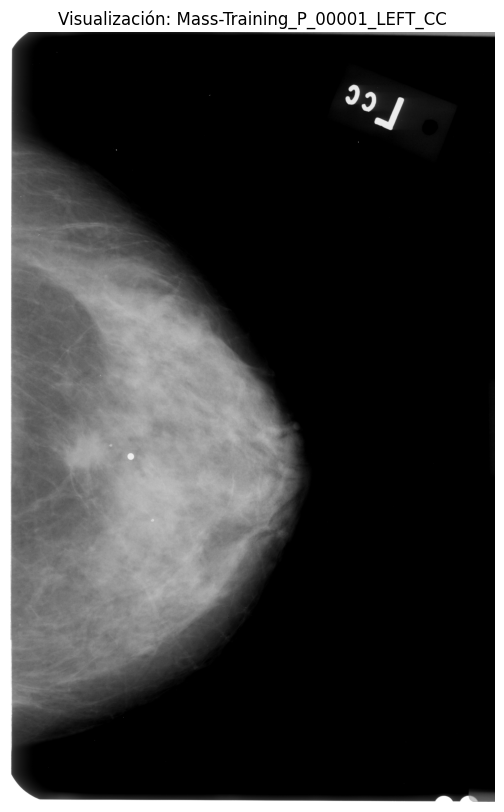

In [8]:
import matplotlib.pyplot as plt

# Tomamos el primer archivo DICOM encontrado
if archivos:
    f = archivos[0]
    ds = pydicom.dcmread(f)

    if "pixel_array" in dir(ds):
        plt.figure(figsize=(10, 10))
        # Mostramos la imagen en escala de grises, que es el estándar para mamografías
        plt.imshow(ds.pixel_array, cmap="gray")
        plt.title(f"Visualización: {ds.get('PatientID', f.name)}")
        plt.axis("off")  # Ocultamos los ejes para centrar la atención en la imagen
        plt.show()
    else:
        print("El archivo DICOM no contiene una matriz de píxeles visualizable.")
else:
    print("No se encontraron archivos DICOM para visualizar.")

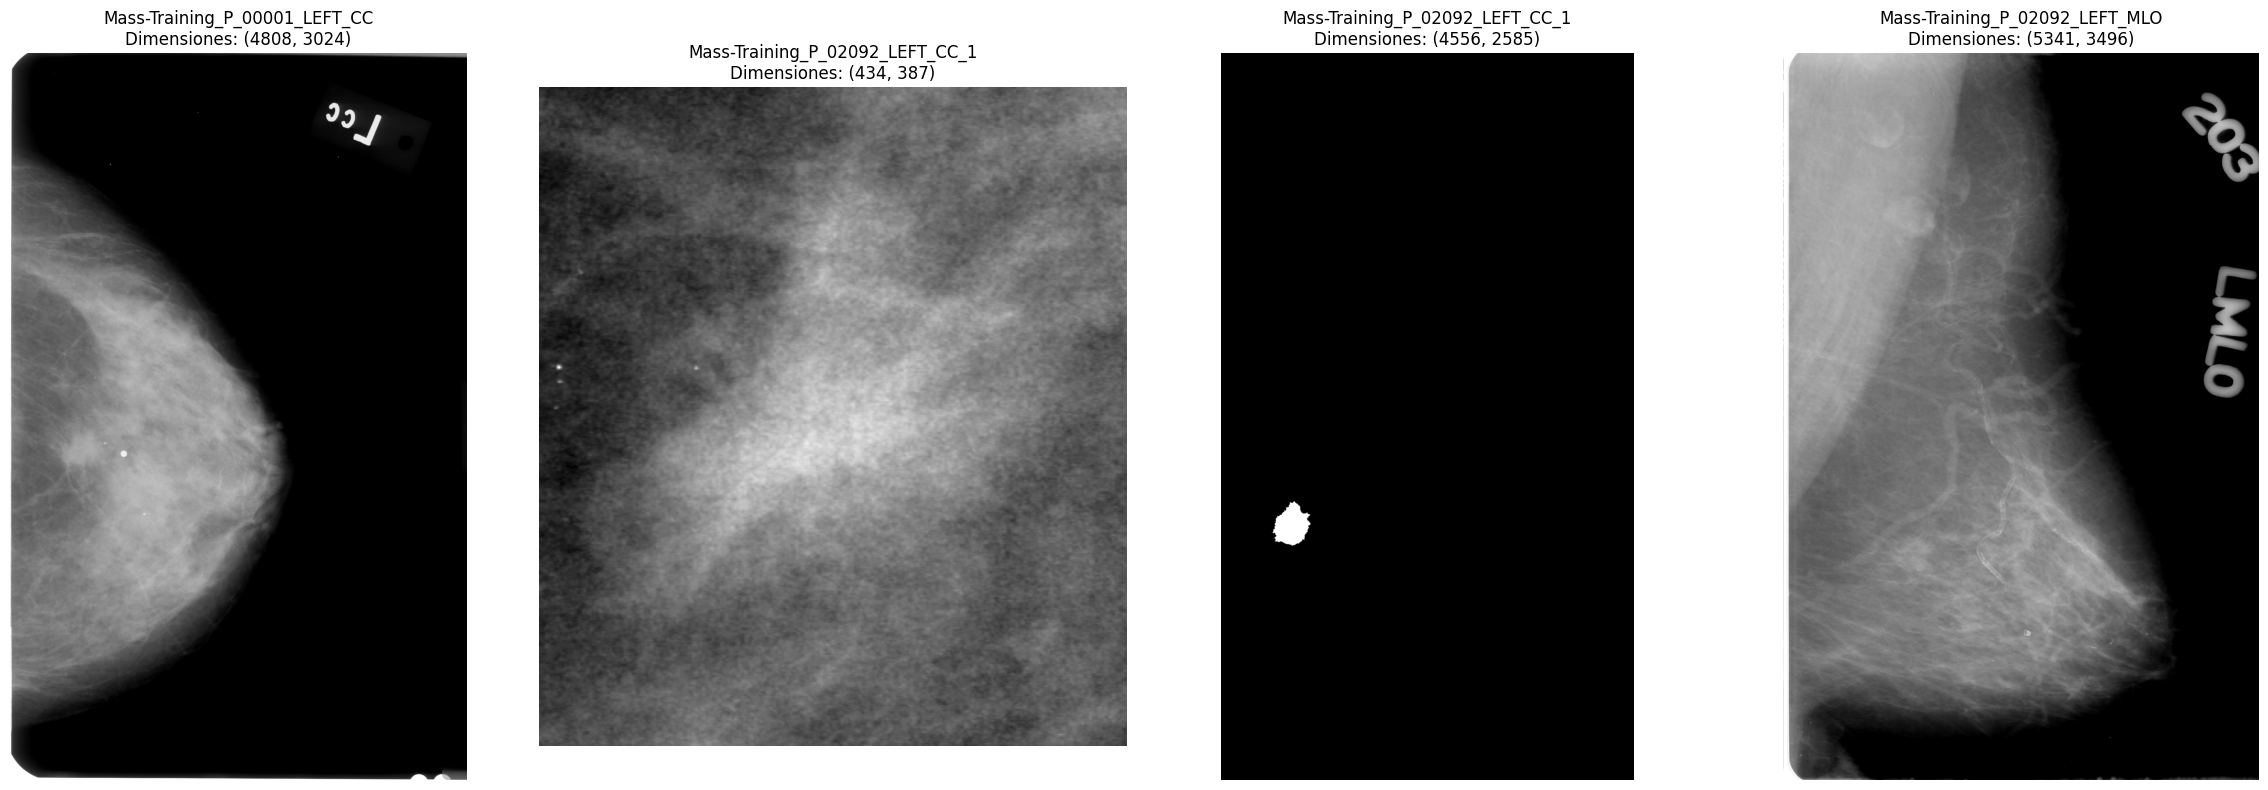

In [15]:
import matplotlib.pyplot as plt

# Verificamos si hay archivos disponibles
if archivos:
    num_imagenes = len(archivos)
    # Creamos un lienzo con subplots (una fila, tantas columnas como imágenes tengamos)
    fig, axes = plt.subplots(1, num_imagenes, figsize=(6 * num_imagenes, 8))

    # Si solo hay una imagen, convertimos axes en una lista para poder iterar
    if num_imagenes == 1:
        axes = [axes]

    for i, f in enumerate(archivos):
        ds = pydicom.dcmread(f)
        ax = axes[i]

        if "pixel_array" in dir(ds):
            ax.imshow(ds.pixel_array, cmap="gray")
            ax.set_title(f"{ds.get('PatientID', f.name)}\nDimensiones: {ds.pixel_array.shape}")
        else:
            ax.text(0.5, 0.5, "Sin imagen usable", ha="center", va="center")
            ax.set_title(f.name)

        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron archivos DICOM para visualizar.")